# Train FRB CNN

Trains a CNN to classify CHIME/FRB-style dynamic-spectrum images as **burst** (label 1, from
`simulate_frbs_fitburst2.py`) vs **not a burst** (label 0, from `simulate_rfi.py`).

Expects two folders of `.npz` files, each with a `data_full` array (`num_freq x num_time`,
`num_freq` fixed at 256, `num_time` varies per-sample between 32 and 512) and a `metadata` dict.

```
project/
|-- sim_output2/      <- from simulate_frbs_fitburst2.py (label 1)
|-- sim_output_rfi/   <- from simulate_rfi.py             (label 0)
`-- train_frb_cnn.ipynb  <- this notebook
```

**Design choices** (carried over from the original script):
- Variable time length → every image is resized (linear interp) to a fixed `(FREQ_BINS, TIME_BINS)` grid.
- Per-image robust normalization (median/MAD), not a global scaler.
- Class balance is **not** assumed 50/50 — a `WeightedRandomSampler` + `pos_weight` handle imbalance.
- Split is done by file, stratified by label, with a fixed seed (no leakage).
- A final **Results** section at the end gives training curves, confusion matrix, ROC/PR curves,
  a classification report, and a grid of example predictions.

## 1. Imports

In [1]:
import json
import os
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
except ImportError as e:
    raise SystemExit(
        "This notebook needs PyTorch. Install it first, e.g.:\n"
        "  pip install torch --break-system-packages\n"
        f"(original error: {e})"
    )

from sklearn.metrics import (
    confusion_matrix, roc_curve, auc, precision_recall_curve,
    average_precision_score, classification_report,
)

## 2. Configuration

Everything that was a `--flag` in the original `argparse` CLI is just a variable here — edit and
re-run this cell instead of passing command-line args.

**Running on an Apple Silicon GPU (M1/M2/M3/M4):** these Macs don't have CUDA, but PyTorch can use
the on-chip GPU through the **MPS** (Metal Performance Shaders) backend. Requirements:
- macOS 12.3+
- `torch >= 1.12` installed as the normal (non-CUDA) build — `pip install torch --break-system-packages`
  is fine, there's no separate "Mac GPU" package
- Check it's available: `python3 -c "import torch; print(torch.backends.mps.is_available())"` should print `True`

Section 6 below auto-detects `cuda` → `mps` → `cpu`, in that order, so nothing else needs to change.

In [2]:
FREQ_BINS = 256   # matches NUM_FREQ in both simulators -- kept as a constant,
                   # not re-derived, so a mismatched file fails loudly
TIME_BINS = 256    # fixed resize target for the time axis (native range is 32-512)

FRB_DIR = "sim_output"       # simulate_frbs_fitburst2.py output (label 1)
RFI_DIR = "sim_output_rfi"    # simulate_rfi.py output (label 0)
OUTDIR = "runs/exp3"

EPOCHS = 25
BATCH_SIZE = 32
LR = 1e-3
WEIGHT_DECAY = 1e-4
VAL_FRAC = 0.15
TEST_FRAC = 0.15
SEED = 42
PATIENCE = 6           # early-stopping patience (epochs without val F1 improvement)
NUM_WORKERS = 0
FORCE_CPU = False      # set True to force CPU even if a GPU/MPS device is available

# --- data augmentation (train split only -- see chat) ---
# Forces the model to be invariant to exact position/channel-pattern/noise
# realization, so anything that survives augmentation is more likely to be
# real burst structure rather than a fixed pixel-level artifact. This is
# also a second, independent check on the shortcut-learning question from
# the earlier review: if performance holds up under these perturbations,
# that's evidence the model isn't just memorizing exact pixel positions.
AUGMENT_TRAIN = True
AUG_TIME_SHIFT_FRAC = 0.08     # random roll along the time axis, up to +/- this fraction of TIME_BINS
AUG_CHANNEL_DROPOUT_FRAC = 0.05  # randomly zero out up to this fraction of frequency channels
AUG_NOISE_STD = 0.05            # additive Gaussian jitter (in already-normalized units)
AUG_PROB = 0.5                   # probability each of the three augmentations is applied per-sample

os.makedirs(OUTDIR, exist_ok=True)

## 3. Dataset

In [3]:
class DynSpecDataset(Dataset):
    """Loads .npz dynamic-spectrum files from an FRB dir (label 1) and an
    RFI dir (label 0), resizes each to (FREQ_BINS, TIME_BINS), and applies
    per-image robust normalization. When augment=True (train split only),
    also applies random time-shift, channel dropout, and noise jitter."""

    def __init__(self, files_labels, augment=False):
        # files_labels: list of (path, label) tuples
        self.files_labels = files_labels
        self.augment = augment

    def __len__(self):
        return len(self.files_labels)

    @staticmethod
    def _load_array(path: str) -> np.ndarray:
        npz = np.load(path, allow_pickle=True)
        arr = npz["data_full"].astype(np.float32)
        if arr.shape[0] != FREQ_BINS:
            raise ValueError(f"{path}: expected {FREQ_BINS} freq channels, got {arr.shape[0]}")
        return arr

    @staticmethod
    def _resize_time_axis(arr: np.ndarray, target_time: int) -> np.ndarray:
        """Linear interpolation along the time axis only (freq axis is
        already fixed at FREQ_BINS in both simulators)."""
        t_native = arr.shape[1]
        if t_native == target_time:
            return arr
        x_old = np.linspace(0.0, 1.0, t_native)
        x_new = np.linspace(0.0, 1.0, target_time)
        out = np.empty((arr.shape[0], target_time), dtype=np.float32)
        for i in range(arr.shape[0]):
            out[i] = np.interp(x_new, x_old, arr[i])
        return out

    @staticmethod
    def _robust_normalize(arr: np.ndarray) -> np.ndarray:
        """Per-image median/MAD normalization. Zeroed-out RFI-masked
        channels (exact zeros) are common to both classes by design, so
        they're excluded from the statistics to avoid biasing the scale."""
        nonzero = arr[arr != 0.0]
        if nonzero.size < 10:
            med, mad = 0.0, 1.0
        else:
            med = np.median(nonzero)
            mad = np.median(np.abs(nonzero - med)) + 1e-6
        return (arr - med) / (1.4826 * mad)

    @staticmethod
    def _augment(arr: np.ndarray) -> np.ndarray:
        """Random time-shift + channel dropout + noise jitter, each
        applied independently with probability AUG_PROB. Done on the
        already-resized, already-normalized array, so the perturbations are
        in a consistent, model-facing scale rather than raw instrumental
        units."""
        if np.random.random() < AUG_PROB:
            max_shift = max(1, int(AUG_TIME_SHIFT_FRAC * arr.shape[1]))
            shift = np.random.randint(-max_shift, max_shift + 1)
            if shift != 0:
                arr = np.roll(arr, shift, axis=1)
        if np.random.random() < AUG_PROB:
            n_drop = int(AUG_CHANNEL_DROPOUT_FRAC * arr.shape[0])
            if n_drop > 0:
                drop_idx = np.random.choice(arr.shape[0], size=n_drop, replace=False)
                arr = arr.copy()
                arr[drop_idx, :] = 0.0
        if np.random.random() < AUG_PROB:
            arr = arr + np.random.normal(0.0, AUG_NOISE_STD, size=arr.shape).astype(np.float32)
        return arr

    def __getitem__(self, idx):
        path, label = self.files_labels[idx]
        arr = self._load_array(path)
        arr = self._resize_time_axis(arr, TIME_BINS)
        arr = self._robust_normalize(arr)
        if self.augment:
            arr = self._augment(arr)
        arr = np.clip(arr, -8.0, 8.0)  # tame rare outlier pixels post-normalization
        # Last-resort safety net: a poisoned upstream file should never be
        # allowed to reach the model -- one NaN batch permanently NaNs
        # every weight via backprop. filter_finite_files() below already
        # removes these at dataset-build time; this just makes __getitem__
        # itself unable to emit a non-finite tensor even if that step was
        # skipped or a new bad file appears later.
        arr = np.nan_to_num(arr, nan=0.0, posinf=8.0, neginf=-8.0)
        tensor = torch.from_numpy(np.ascontiguousarray(arr)).unsqueeze(0)  # (1, F, T)
        return tensor, torch.tensor(label, dtype=torch.float32)

In [4]:
def filter_finite_files(files_labels, desc="scanning"):
    """Open every .npz up front and drop any whose data_full array
    contains NaN/Inf, BEFORE training starts. One non-finite image
    getting backpropagated through permanently NaNs every model weight
    (loss.backward() -> NaN gradient -> optimizer.step() writes NaN into
    every parameter -> every subsequent epoch is stuck predicting the same
    constant class, exactly the flat val P=0 R=0 F1=0 pattern). Cheap
    relative to a wasted 25-epoch training run."""
    clean, bad = [], []
    for path, label in files_labels:
        try:
            arr = np.load(path, allow_pickle=True)["data_full"]
        except Exception as e:
            bad.append((path, f"failed to load: {e}"))
            continue
        if not np.all(np.isfinite(arr)):
            bad.append((path, "contains NaN/Inf"))
            continue
        clean.append((path, label))

    print(f"[{desc}] {len(clean)} clean / {len(bad)} rejected out of {len(files_labels)} files")
    if bad:
        for path, reason in bad[:20]:
            print(f"  rejected: {path} ({reason})")
        if len(bad) > 20:
            print(f"  ... and {len(bad) - 20} more")
    return clean


def build_file_label_list(frb_dir: str, rfi_dir: str):
    frb_files = sorted(Path(frb_dir).glob("*.npz"))
    rfi_files = sorted(Path(rfi_dir).glob("*.npz"))
    if not frb_files:
        raise SystemExit(f"No .npz files found in --frb-dir {frb_dir}")
    if not rfi_files:
        raise SystemExit(f"No .npz files found in --rfi-dir {rfi_dir}")
    items = [(str(p), 1) for p in frb_files] + [(str(p), 0) for p in rfi_files]
    return items


def stratified_split(items, val_frac=0.15, test_frac=0.15, seed=42):
    rng = random.Random(seed)
    pos = [x for x in items if x[1] == 1]
    neg = [x for x in items if x[1] == 0]
    rng.shuffle(pos)
    rng.shuffle(neg)

    def split_one(lst):
        n = len(lst)
        n_val = int(round(n * val_frac))
        n_test = int(round(n * test_frac))
        test = lst[:n_test]
        val = lst[n_test:n_test + n_val]
        train = lst[n_test + n_val:]
        return train, val, test

    p_tr, p_va, p_te = split_one(pos)
    n_tr, n_va, n_te = split_one(neg)
    train = p_tr + n_tr
    val = p_va + n_va
    test = p_te + n_te
    rng.shuffle(train)
    rng.shuffle(val)
    rng.shuffle(test)
    return train, val, test

## 4. Model

In [5]:
class FRBCNN(nn.Module):
    """Small CNN, deliberately shallow: dynamic spectra here are 256x256
    single-channel images with a fairly simple discriminating structure
    (a bright, drifting/dispersed ridge vs banding/noise/RFI streaks), so a
    deep ImageNet-style net is unnecessary and more prone to overfitting on
    a few thousand simulated images."""

    def __init__(self, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=5, padding=2), nn.BatchNorm2d(16), nn.ReLU(),
            nn.MaxPool2d(2),  # 256 -> 128

            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),  # 128 -> 64

            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),  # 64 -> 32

            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d(4),  # -> 4x4, size-agnostic just in case
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x).squeeze(1)  # raw logits

## 5. Train / eval loop

In [6]:
def run_epoch(model, loader, device, optimizer=None, pos_weight=None):
    is_train = optimizer is not None
    model.train(is_train)
    total_loss, all_logits, all_labels = 0.0, [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.set_grad_enabled(is_train):
            logits = model(x)
            loss = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight)
            if is_train:
                if not torch.isfinite(loss):
                    # Should be unreachable now that filter_finite_files()
                    # screens the dataset up front, but if it ever happens
                    # again, skip this batch's update instead of writing
                    # NaN into every model weight permanently.
                    print("  WARNING: non-finite loss on a training batch -- skipping this update")
                    continue
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()
        total_loss += loss.item() * x.size(0)
        all_logits.append(logits.detach().cpu())
        all_labels.append(y.detach().cpu())

    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels)
    preds = (torch.sigmoid(logits) > 0.5).float()
    acc = (preds == labels).float().mean().item()

    tp = ((preds == 1) & (labels == 1)).sum().item()
    fp = ((preds == 1) & (labels == 0)).sum().item()
    fn = ((preds == 0) & (labels == 1)).sum().item()
    tn = ((preds == 0) & (labels == 0)).sum().item()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-8)

    metrics = {
        "loss": total_loss / len(loader.dataset),
        "acc": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    }
    return metrics


@torch.no_grad()
def collect_predictions(model, loader, device):
    """Like run_epoch's eval path, but also returns per-sample probs/labels
    (and the raw images) for building the results visualizations below."""
    model.eval()
    all_probs, all_labels, all_imgs = [], [], []
    for x, y in loader:
        logits = model(x.to(device))
        probs = torch.sigmoid(logits).cpu()
        all_probs.append(probs)
        all_labels.append(y)
        all_imgs.append(x)
    return (torch.cat(all_probs).numpy(),
            torch.cat(all_labels).numpy(),
            torch.cat(all_imgs).numpy())

## 6. Build datasets & loaders

Augmentation (time-shift, channel dropout, noise jitter) is applied to the **training** split
only — validation and test stay unaugmented so metrics reflect clean, honest performance.

In [7]:
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

def pick_device(force_cpu: bool) -> torch.device:
    if force_cpu:
        return torch.device("cpu")
    if torch.cuda.is_available():          # NVIDIA GPU
        return torch.device("cuda")
    if torch.backends.mps.is_available():  # Apple Silicon GPU (M1/M2/M3/M4) via Metal
        return torch.device("mps")
    return torch.device("cpu")

device = pick_device(FORCE_CPU)
print(f"Using device: {device}")
if device.type == "cpu" and torch.backends.mps.is_built():
    print("  (MPS backend is built into this torch install but not available right now -- "
          "see the troubleshooting note in the config cell above.)")

items = build_file_label_list(FRB_DIR, RFI_DIR)
items = filter_finite_files(items, desc="pre-training NaN/Inf scan")
n_pos = sum(1 for _, l in items if l == 1)
n_neg = sum(1 for _, l in items if l == 0)
print(f"After NaN/Inf filtering: {n_pos} FRB images, {n_neg} RFI images")
if n_pos == 0 or n_neg == 0:
    raise SystemExit("One class has zero clean images after filtering -- check the simulator output.")

train_items, val_items, test_items = stratified_split(items, val_frac=VAL_FRAC, test_frac=TEST_FRAC, seed=SEED)
print(f"Split: train={len(train_items)}  val={len(val_items)}  test={len(test_items)}")

train_ds = DynSpecDataset(train_items, augment=AUGMENT_TRAIN)
val_ds = DynSpecDataset(val_items, augment=False)    # never augment val/test -- honest, stable metrics
test_ds = DynSpecDataset(test_items, augment=False)

# Balance classes in the TRAINING loader only, via inverse-frequency
# sample weights (val/test stay at natural distribution for honest metrics).
train_labels = np.array([l for _, l in train_items])
class_count = np.bincount(train_labels, minlength=2)
sample_weights = 1.0 / class_count[train_labels]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

Using device: mps
[pre-training NaN/Inf scan] 8608 clean / 0 rejected out of 8608 files
After NaN/Inf filtering: 4081 FRB images, 4527 RFI images
Split: train=6026  val=1291  test=1291


## 6.5 Verify augmentation is actually running

Direct proof, not just trusting the code path: pull the *same* training image twice through
`train_ds` and confirm the two returned tensors differ (since `_augment()` calls `np.random`
each time it runs), then plot a clean vs. an augmented version side by side so you can see the
time-shift/channel-dropout/noise-jitter with your own eyes.

train_ds.augment = True
Two loads of the same training image are identical: False
  -> confirmed: augmentation is actively changing the image on each load.


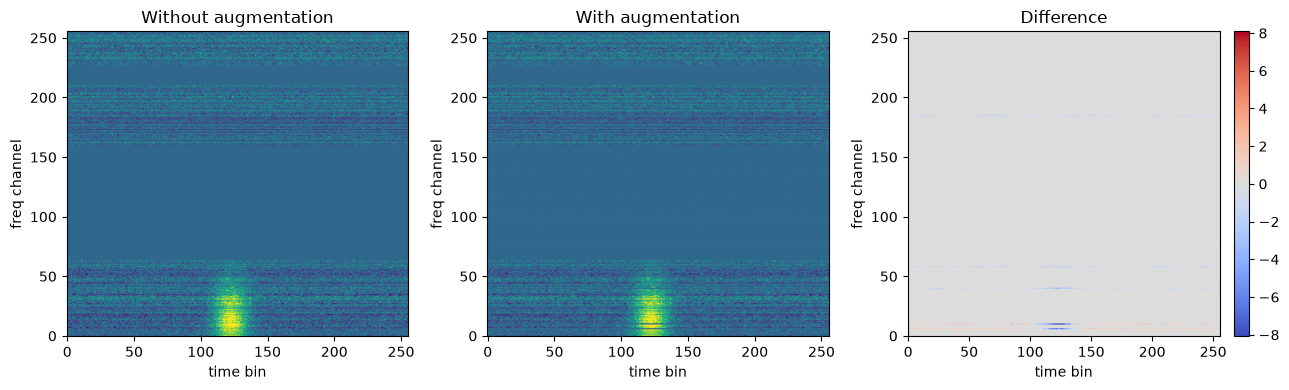

Difference image is non-zero (max abs diff = 8.090) -- 
augmentation visibly changed this image (took 1 attempt(s) to see it fire).
Confirmed working.


In [8]:
sample_idx = 0  # any training-set index

# --- statistical check: same index, two calls, should NOT be identical if augment=True ---
img_a, _ = train_ds[sample_idx]
img_b, _ = train_ds[sample_idx]
identical = torch.equal(img_a, img_b)
print(f"train_ds.augment = {train_ds.augment}")
print(f"Two loads of the same training image are identical: {identical}")
if train_ds.augment and identical:
    print("  ^ WARNING: augmentation is ON but two loads came back identical.")
    print("    This can legitimately happen sometimes -- AUG_PROB=0.5 for each of 3")
    print("    independent augmentations means there's a (1-0.5)^3 = 12.5% chance none of")
    print("    them fire on any given call. Re-run this cell a few times; if it's ALWAYS")
    print("    identical, something is wrong (e.g. train_ds.augment got reset to False).")
elif train_ds.augment:
    print("  -> confirmed: augmentation is actively changing the image on each load.")
else:
    print("  -> expected: train_ds.augment is False, so no randomness should appear.")

# --- visual check: force augment on/off on this dataset instance and compare directly ---
# NOTE: earlier version of this cell seeded np.random to a fixed value (0) right before the
# "with augmentation" load, for reproducibility. That was a bug: with AUG_PROB=0.5 across 3
# independent coin-flips, seed 0 happens to draw values that skip ALL THREE augmentations
# every time -- making the demo deterministically show "no change" regardless of whether
# augmentation actually works. Fixed by NOT forcing a seed, and instead retrying a few times
# (genuinely random each attempt) until at least one augmentation visibly fires.
original_flag = train_ds.augment
train_ds.augment = False
clean_img, _ = train_ds[sample_idx]
train_ds.augment = True

aug_img, diff = None, None
for attempt in range(10):
    candidate, _ = train_ds[sample_idx]
    candidate_diff = (candidate[0] - clean_img[0]).numpy()
    if not np.allclose(candidate_diff, 0.0):
        aug_img, diff = candidate, candidate_diff
        break
train_ds.augment = original_flag  # restore whatever AUGMENT_TRAIN actually set

if aug_img is None:
    print("\nNo augmentation fired in 10 attempts -- with AUG_PROB=0.5 x 3 this is astronomically")
    print("unlikely ((1-0.5)^3)^10 =~ 6e-9 -- if you see this, augmentation is genuinely not running.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(clean_img[0].numpy(), aspect="auto", origin="lower", cmap="viridis")
    axes[0].set_title("Without augmentation")
    axes[1].imshow(aug_img[0].numpy(), aspect="auto", origin="lower", cmap="viridis")
    axes[1].set_title("With augmentation")
    im = axes[2].imshow(diff, aspect="auto", origin="lower", cmap="coolwarm",
                         vmin=-np.abs(diff).max(), vmax=np.abs(diff).max())
    axes[2].set_title("Difference")
    fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
    for ax in axes:
        ax.set_xlabel("time bin"); ax.set_ylabel("freq channel")
    plt.tight_layout()
    plt.show()
    print(f"Difference image is non-zero (max abs diff = {np.abs(diff).max():.3f}) -- ")
    print(f"augmentation visibly changed this image (took {attempt + 1} attempt(s) to see it fire).")
    print("Confirmed working.")

## 7. Train

In [9]:
model = FRBCNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

# Also pass a mild pos_weight to the loss itself (belt-and-suspenders
# with the sampler above -- harmless if classes are already close to balanced).
pos_weight = torch.tensor([n_neg / max(n_pos, 1)], dtype=torch.float32).to(device)

best_f1 = -1.0
epochs_no_improve = 0
history = []
best_path = os.path.join(OUTDIR, "best_model.pt")

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(model, train_loader, device, optimizer=optimizer, pos_weight=pos_weight)
    val_metrics = run_epoch(model, val_loader, device, optimizer=None, pos_weight=pos_weight)
    scheduler.step(val_metrics["f1"])

    print(f"Epoch {epoch:03d} | "
          f"train loss {train_metrics['loss']:.4f} acc {train_metrics['acc']:.3f} | "
          f"val loss {val_metrics['loss']:.4f} acc {val_metrics['acc']:.3f} "
          f"P {val_metrics['precision']:.3f} R {val_metrics['recall']:.3f} F1 {val_metrics['f1']:.3f}")

    history.append({"epoch": epoch, "train": train_metrics, "val": val_metrics})

    if val_metrics["f1"] > best_f1:
        best_f1 = val_metrics["f1"]
        epochs_no_improve = 0
        torch.save({"model_state": model.state_dict(),
                    "epoch": epoch,
                    "val_f1": best_f1,
                    "freq_bins": FREQ_BINS,
                    "time_bins": TIME_BINS}, best_path)
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping at epoch {epoch} (no val F1 improvement for {PATIENCE} epochs)")
            break

with open(os.path.join(OUTDIR, "history.json"), "w") as f:
    json.dump(history, f, indent=2)

Epoch 001 | train loss 0.2899 acc 0.883 | val loss 0.1162 acc 0.959 P 0.978 R 0.935 F1 0.956
Epoch 002 | train loss 0.1368 acc 0.956 | val loss 0.1344 acc 0.955 P 0.963 R 0.941 F1 0.952
Epoch 003 | train loss 0.1102 acc 0.967 | val loss 0.1001 acc 0.971 P 0.975 R 0.964 F1 0.970
Epoch 004 | train loss 0.0975 acc 0.970 | val loss 0.0907 acc 0.976 P 0.985 R 0.964 F1 0.974
Epoch 005 | train loss 0.0867 acc 0.973 | val loss 0.0919 acc 0.973 P 0.987 R 0.956 F1 0.971
Epoch 006 | train loss 0.0921 acc 0.968 | val loss 0.1031 acc 0.966 P 0.977 R 0.951 F1 0.964
Epoch 007 | train loss 0.0797 acc 0.976 | val loss 0.0831 acc 0.974 P 0.969 R 0.977 F1 0.973
Epoch 008 | train loss 0.0670 acc 0.981 | val loss 0.0956 acc 0.970 P 0.977 R 0.959 F1 0.968
Epoch 009 | train loss 0.0409 acc 0.988 | val loss 0.0675 acc 0.980 P 0.973 R 0.985 F1 0.979
Epoch 010 | train loss 0.0454 acc 0.987 | val loss 0.0807 acc 0.970 P 0.958 R 0.979 F1 0.968
Epoch 011 | train loss 0.0379 acc 0.989 | val loss 0.0739 acc 0.978 P 

## 8. Final test-set evaluation

Reloads the best checkpoint (by val F1) and evaluates once on the held-out test set.

In [10]:
ckpt = torch.load(best_path, map_location=device)
model.load_state_dict(ckpt["model_state"])
test_metrics = run_epoch(model, test_loader, device, optimizer=None, pos_weight=pos_weight)
print("=== Test set (best checkpoint, epoch {}) ===".format(ckpt["epoch"]))
print(f"acc={test_metrics['acc']:.3f}  precision={test_metrics['precision']:.3f}  "
      f"recall={test_metrics['recall']:.3f}  f1={test_metrics['f1']:.3f}")
print(f"confusion matrix: TP={test_metrics['tp']} FP={test_metrics['fp']} "
      f"FN={test_metrics['fn']} TN={test_metrics['tn']}")

with open(os.path.join(OUTDIR, "test_metrics.json"), "w") as f:
    json.dump(test_metrics, f, indent=2)

print(f"\nBest model saved to {best_path}")

=== Test set (best checkpoint, epoch 12) ===
acc=0.982  precision=0.980  recall=0.982  f1=0.981
confusion matrix: TP=601 FP=12 FN=11 TN=667

Best model saved to runs/exp3/best_model.pt


---
## 9. Results

Everything below is new relative to the original script: training curves, a confusion matrix,
ROC/PR curves, a full classification report, and a grid of example predictions -- all computed
on the held-out **test** set using the best checkpoint loaded above.

### 9.1 Training curves

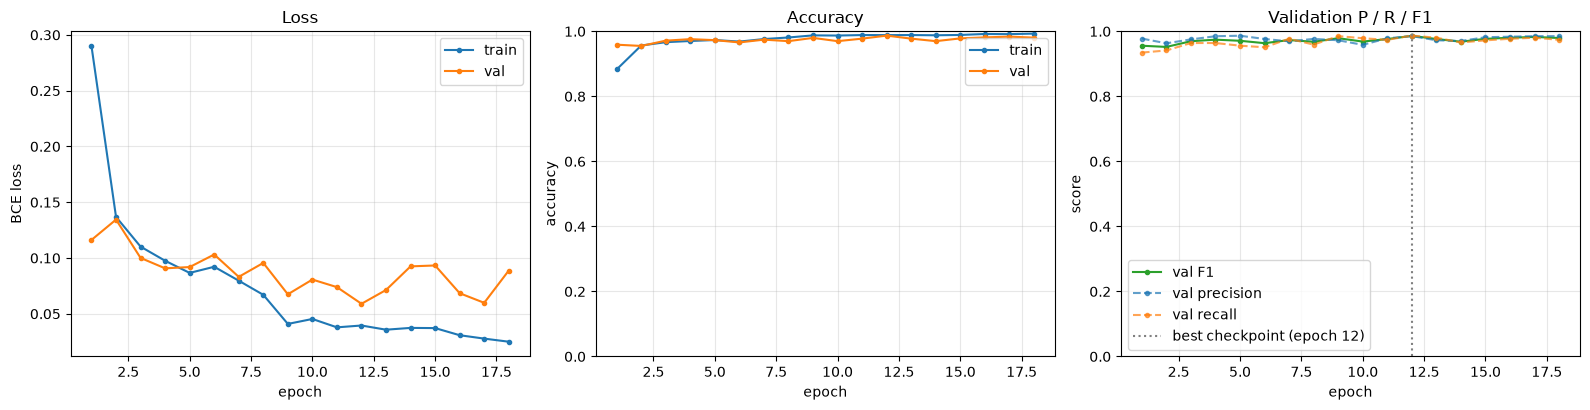

In [11]:
epochs_ran = [h["epoch"] for h in history]
train_loss = [h["train"]["loss"] for h in history]
val_loss = [h["val"]["loss"] for h in history]
train_acc = [h["train"]["acc"] for h in history]
val_acc = [h["val"]["acc"] for h in history]
val_f1 = [h["val"]["f1"] for h in history]
val_prec = [h["val"]["precision"] for h in history]
val_rec = [h["val"]["recall"] for h in history]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].plot(epochs_ran, train_loss, label="train", marker="o", ms=3)
axes[0].plot(epochs_ran, val_loss, label="val", marker="o", ms=3)
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("BCE loss")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_ran, train_acc, label="train", marker="o", ms=3)
axes[1].plot(epochs_ran, val_acc, label="val", marker="o", ms=3)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
axes[1].set_ylim(0, 1)
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(epochs_ran, val_f1, label="val F1", marker="o", ms=3, color="tab:green")
axes[2].plot(epochs_ran, val_prec, label="val precision", marker="o", ms=3, linestyle="--", alpha=0.7)
axes[2].plot(epochs_ran, val_rec, label="val recall", marker="o", ms=3, linestyle="--", alpha=0.7)
best_epoch = ckpt["epoch"]
axes[2].axvline(best_epoch, color="gray", linestyle=":", label=f"best checkpoint (epoch {best_epoch})")
axes[2].set_title("Validation P / R / F1")
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("score")
axes[2].set_ylim(0, 1)
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "training_curves.png"), dpi=150)
plt.show()

### 9.2 Test-set predictions (for the plots below)

In [12]:
test_probs, test_labels, test_imgs = collect_predictions(model, test_loader, device)
test_preds = (test_probs > 0.5).astype(int)
# test_loader has shuffle=False, so this lines up 1:1 with test_probs/test_labels/test_imgs --
# needed below to look each image's true burst position up from its .npz metadata.
test_paths = [p for p, _ in test_items]
print(f"Collected {len(test_labels)} test predictions "
      f"({int(test_labels.sum())} FRB / {int((1 - test_labels).sum())} RFI)")

Collected 1291 test predictions (612 FRB / 679 RFI)


### 9.3 Confusion matrix

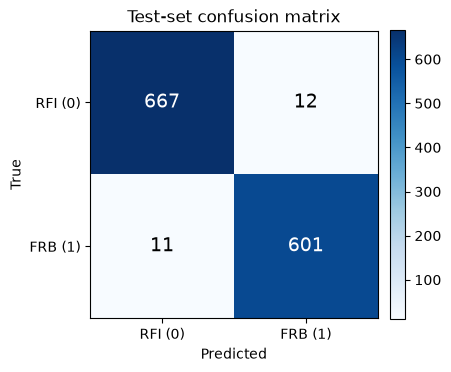

In [13]:
cm = confusion_matrix(test_labels, test_preds, labels=[0, 1])

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["RFI (0)", "FRB (1)"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["RFI (0)", "FRB (1)"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Test-set confusion matrix")
for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=color, fontsize=14)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "confusion_matrix.png"), dpi=150)
plt.show()

### 9.4 ROC and precision-recall curves

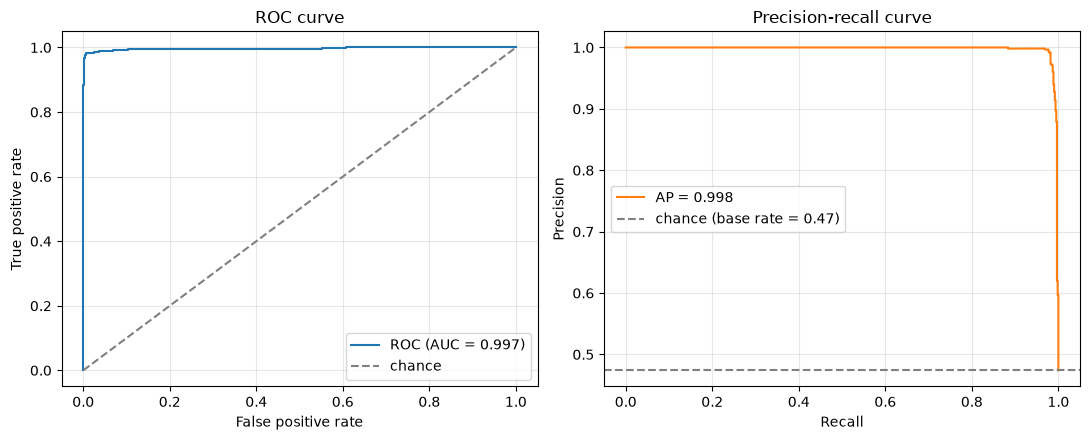

In [14]:
fpr, tpr, _ = roc_curve(test_labels, test_probs)
roc_auc = auc(fpr, tpr)
prec_curve, rec_curve, _ = precision_recall_curve(test_labels, test_probs)
ap = average_precision_score(test_labels, test_probs)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(fpr, tpr, label=f"ROC (AUC = {roc_auc:.3f})", color="tab:blue")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="chance")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(rec_curve, prec_curve, label=f"AP = {ap:.3f}", color="tab:orange")
base_rate = test_labels.mean()
axes[1].axhline(base_rate, linestyle="--", color="gray", label=f"chance (base rate = {base_rate:.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "roc_pr_curves.png"), dpi=150)
plt.show()

### 9.5 Classification report

In [15]:
print(classification_report(test_labels, test_preds, target_names=["RFI (0)", "FRB (1)"], digits=3))

              precision    recall  f1-score   support

     RFI (0)      0.984     0.982     0.983       679
     FRB (1)      0.980     0.982     0.981       612

    accuracy                          0.982      1291
   macro avg      0.982     0.982     0.982      1291
weighted avg      0.982     0.982     0.982      1291



### 9.6 Example predictions

A grid of test-set dynamic spectra: correctly classified FRBs and RFI, plus any misclassifications
(false positives / false negatives), so you can visually sanity-check what the model gets wrong.

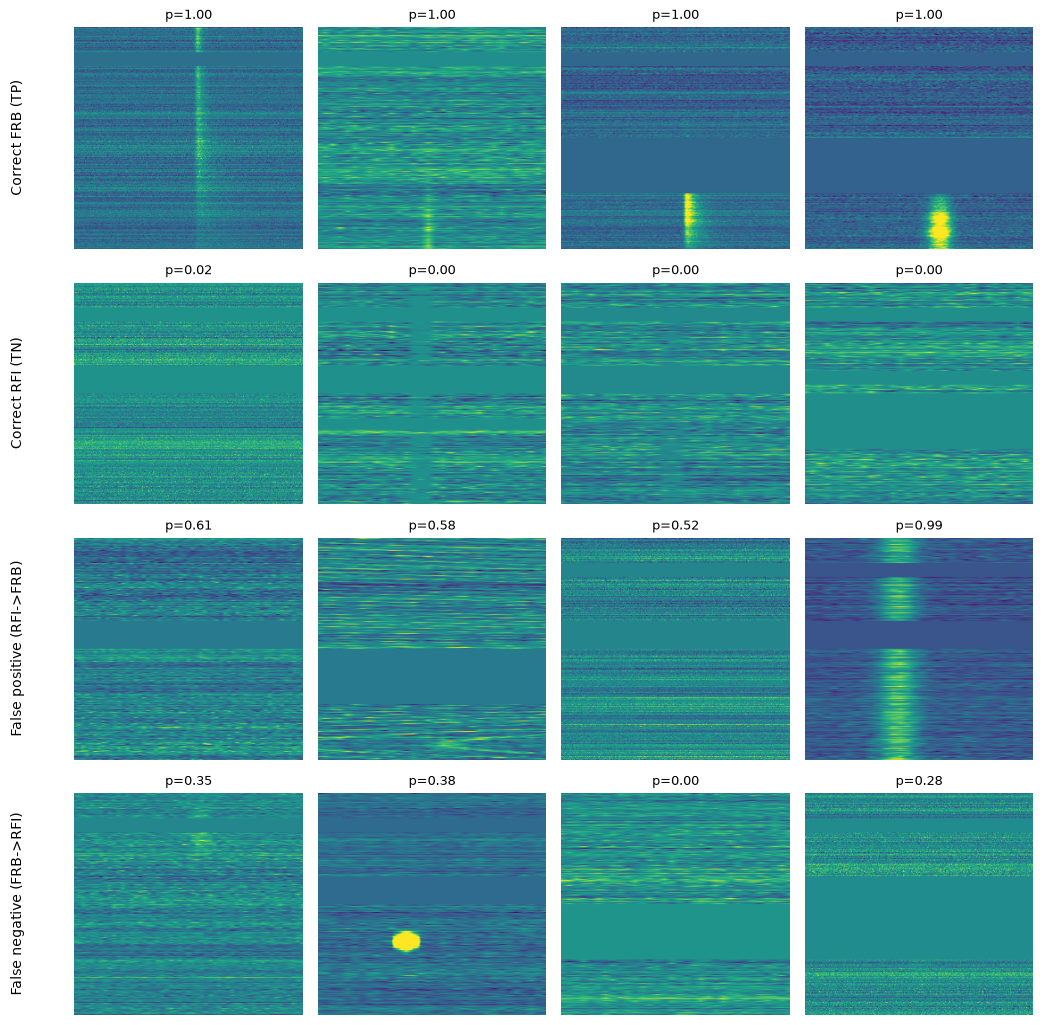

In [16]:
def pick_examples(probs, labels, n=4):
    preds = (probs > 0.5).astype(int)
    idx_tp = np.where((labels == 1) & (preds == 1))[0]
    idx_tn = np.where((labels == 0) & (preds == 0))[0]
    idx_fp = np.where((labels == 0) & (preds == 1))[0]
    idx_fn = np.where((labels == 1) & (preds == 0))[0]
    rng = np.random.default_rng(SEED)
    picks = {}
    for name, idx in [("Correct FRB (TP)", idx_tp), ("Correct RFI (TN)", idx_tn),
                       ("False positive (RFI->FRB)", idx_fp), ("False negative (FRB->RFI)", idx_fn)]:
        picks[name] = rng.choice(idx, size=min(n, len(idx)), replace=False) if len(idx) else np.array([], dtype=int)
    return picks

examples = pick_examples(test_probs, test_labels, n=4)
n_cols = max((len(v) for v in examples.values()), default=1)
n_cols = max(n_cols, 1)
fig, axes = plt.subplots(len(examples), n_cols, figsize=(2.6 * n_cols, 2.6 * len(examples)))
if len(examples) == 1:
    axes = np.array([axes])

for row, (name, idxs) in enumerate(examples.items()):
    for col in range(n_cols):
        ax = axes[row, col] if n_cols > 1 else axes[row]
        ax.axis("off")
        if col < len(idxs):
            i = idxs[col]
            ax.imshow(test_imgs[i, 0], aspect="auto", origin="lower", cmap="viridis")
            ax.set_title(f"p={test_probs[i]:.2f}", fontsize=9)
        if col == 0:
            ax.text(-0.25, 0.5, name, transform=ax.transAxes, rotation=90,
                    va="center", ha="center", fontsize=10)
            ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "example_predictions.png"), dpi=150)
plt.show()

n_fp, n_fn = len(examples["False positive (RFI->FRB)"]), len(examples["False negative (FRB->RFI)"])
if n_fp == 0 and n_fn == 0:
    print("No misclassifications in the test set at the default 0.5 threshold.")

### 9.7 Grad-CAM: what is the model actually looking at?

This is the single most important diagnostic for the shortcut-learning question raised in the
earlier review: near-ceiling accuracy on synthetic data could mean the model learned real burst
morphology (a dispersed/scattered ridge), or it could mean it locked onto some simulator-specific
artifact that happens to correlate with the label (see the `sim_common.py` refactor and the
faint-burst / window-matching fixes from that conversation).

Grad-CAM highlights which pixels the model's last conv layer weighted most heavily for its
prediction. **What to look for:**
- **Good sign:** heat concentrated along the burst's dispersed/scattered ridge for true positives.
- **Bad sign:** heat on image edges, on the RFI-masked (zeroed) channel boundaries, or spread
  uniformly across the whole image regardless of where the burst actually is.

Three things below, all upgraded from a first pass that only eyeballed 4 correct predictions:
1. A larger grid (5 per category, not 4) that now also includes **false positives and false
   negatives** -- what the model attends to when it's *wrong* is often more diagnostic than when
   it's right, and the first pass never looked at this.
2. A **quantitative** alignment check across every correctly-classified FRB in the test set (not
   just the handful pictured): does the Grad-CAM peak column actually land near the burst's real
   injected position (`burst_pos_frac` in each file's metadata), or is that just eyeballing luck
   on 4 cherry-picked images?

In [17]:
class GradCAM:
    """Minimal Grad-CAM for the last conv layer of FRBCNN (before the
    final BatchNorm/ReLU/AdaptiveAvgPool block collapses spatial info)."""

    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activations)
        target_layer.register_full_backward_hook(self._save_gradients)

    def _save_activations(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradients(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def __call__(self, x):
        """x: (1, 1, F, T) tensor, already on the model's device. Returns
        a (F, T) numpy heatmap in [0, 1], upsampled to the input's size."""
        self.model.zero_grad()
        logit = self.model(x)  # (1,)
        logit.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)  # (1, C, 1, 1) -- global-avg-pooled gradient
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))  # (1, 1, h, w)
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam


# Target the last conv layer (features[12]: Conv2d(64,128), the last layer
# with real spatial resolution before BatchNorm/ReLU/AdaptiveAvgPool
# collapse it) -- the conventional Grad-CAM target layer.
target_layer = model.features[12]
assert isinstance(target_layer, nn.Conv2d), (
    f"expected Conv2d at features[12], got {type(target_layer)} -- "
    "model architecture changed? re-check the index against model.features"
)
gradcam = GradCAM(model, target_layer)
model.eval()

FRBCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True

#### 9.7.1 Visual grid: correct AND incorrect predictions

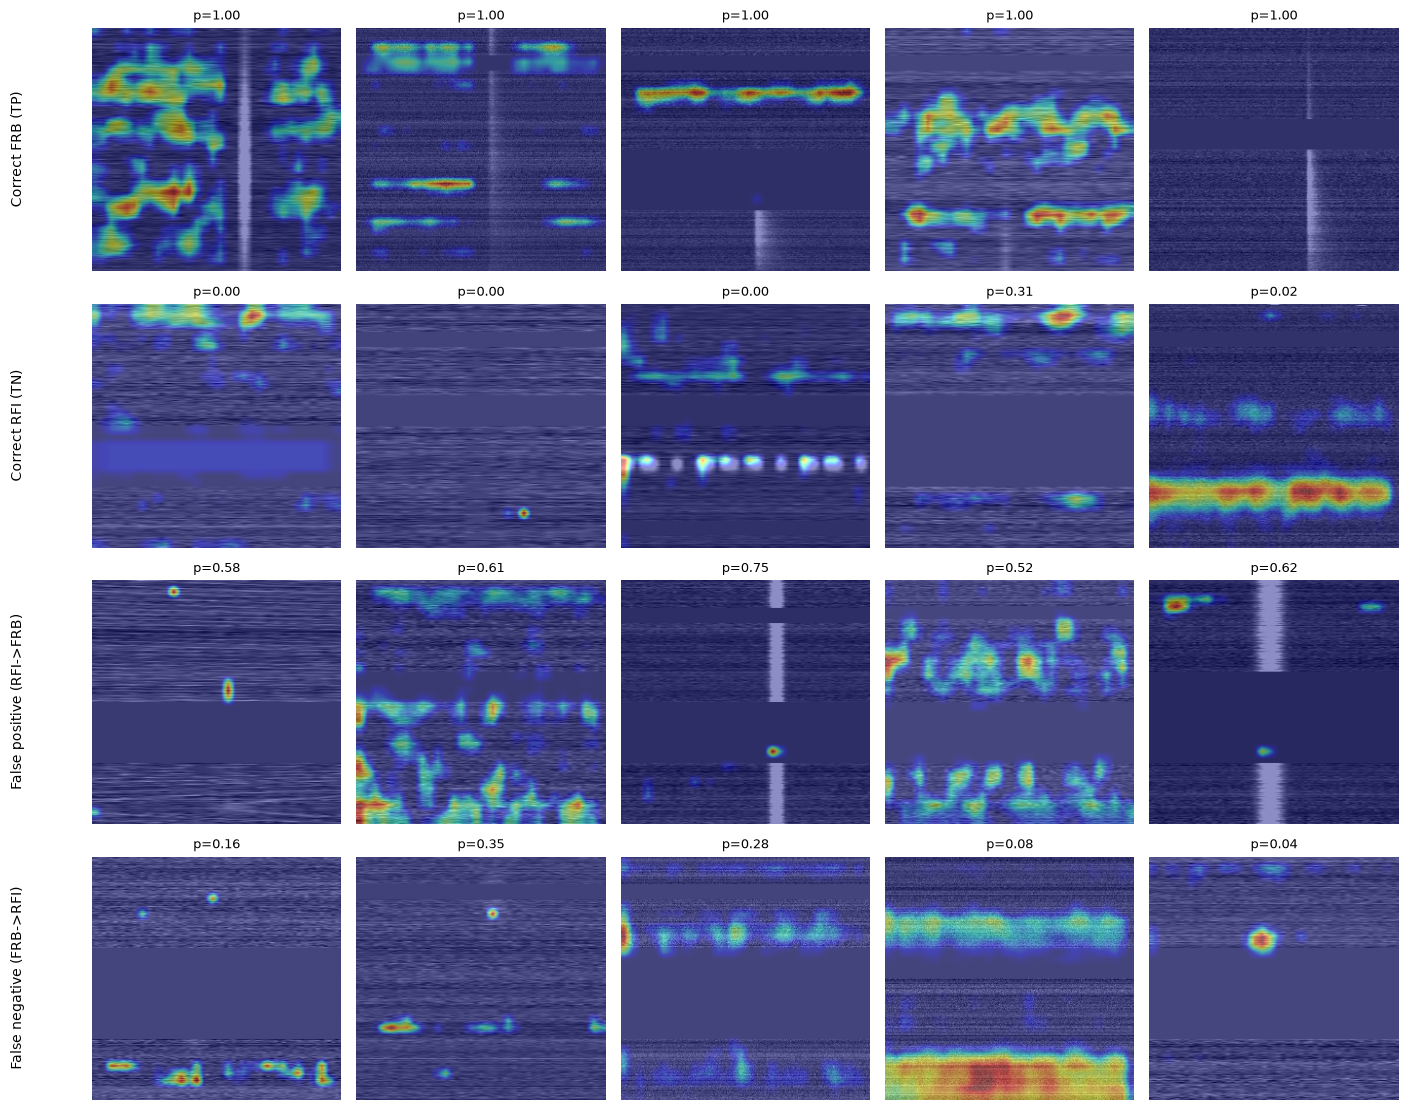

Showing 5 false positive(s) and 5 false negative(s) -- check whether their heat looks like a confused version of a real burst, or something unrelated (e.g. edge/masking artifacts), which would point at a different failure mode.


In [18]:
def pick_gradcam_examples(probs, labels, n=5, seed=SEED):
    preds = (probs > 0.5).astype(int)
    idx_tp = np.where((labels == 1) & (preds == 1))[0]
    idx_tn = np.where((labels == 0) & (preds == 0))[0]
    idx_fp = np.where((labels == 0) & (preds == 1))[0]  # RFI misclassified as FRB
    idx_fn = np.where((labels == 1) & (preds == 0))[0]  # FRB misclassified as RFI
    rng = np.random.default_rng(seed)
    picks = {}
    for name, idx in [("Correct FRB (TP)", idx_tp), ("Correct RFI (TN)", idx_tn),
                       ("False positive (RFI->FRB)", idx_fp), ("False negative (FRB->RFI)", idx_fn)]:
        picks[name] = rng.choice(idx, size=min(n, len(idx)), replace=False) if len(idx) else np.array([], dtype=int)
    return picks

cam_examples = pick_gradcam_examples(test_probs, test_labels, n=5)
n_cols = max((len(v) for v in cam_examples.values()), default=1)
fig, axes = plt.subplots(len(cam_examples), n_cols, figsize=(2.8 * n_cols, 2.8 * len(cam_examples)))
if len(cam_examples) == 1:
    axes = np.array([axes])

for row, (name, idxs) in enumerate(cam_examples.items()):
    for col in range(n_cols):
        ax = axes[row, col] if n_cols > 1 else axes[row]
        ax.axis("off")
        if col >= len(idxs):
            continue
        i = idxs[col]
        img = torch.from_numpy(test_imgs[i:i + 1]).to(device)
        img.requires_grad_(False)
        cam = gradcam(img)
        ax.imshow(test_imgs[i, 0], aspect="auto", origin="lower", cmap="gray")
        ax.imshow(cam, aspect="auto", origin="lower", cmap="jet", alpha=0.45)
        ax.set_title(f"p={test_probs[i]:.2f}", fontsize=9)
        if col == 0:
            ax.text(-0.3, 0.5, name, transform=ax.transAxes, rotation=90,
                    va="center", ha="center", fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, "gradcam_examples.png"), dpi=150)
plt.show()

n_fp_shown, n_fn_shown = len(cam_examples["False positive (RFI->FRB)"]), len(cam_examples["False negative (FRB->RFI)"])
if n_fp_shown == 0 and n_fn_shown == 0:
    print("No misclassifications in the test set to show Grad-CAM for -- every test prediction was correct.")
else:
    print(f"Showing {n_fp_shown} false positive(s) and {n_fn_shown} false negative(s) -- "
          f"check whether their heat looks like a confused version of a real burst, or something "
          f"unrelated (e.g. edge/masking artifacts), which would point at a different failure mode.")

#### 9.7.2 Quantitative check: does Grad-CAM's peak line up with the real burst position?

Eyeballing 5-10 images tells you something, but it's easy to fool yourself either way on a small,
cherry-picked sample. This runs Grad-CAM over **every correctly-classified FRB in the test set**
(capped at `GRADCAM_QUANT_MAX` for speed), looks up each one's true injected time position from
its `.npz` metadata (`burst_pos_frac`, written by the fixed `simulate_frbs_fitburst.py`), and
measures how far the Grad-CAM heatmap's peak column sits from that true position.

**How to read the result:** a tight distribution of small errors (peak column close to the real
burst, most of the time) is real evidence of morphology learning -- the model consistently looks
where the burst actually is. A wide, unstructured, or systematically-offset distribution means the
model's attention isn't actually tracking burst position, which favors the shortcut-learning
explanation regardless of how good the accuracy number looks.

If `burst_pos_frac` is missing from a file's metadata (data generated before that fix), this cell
says so and skips the check rather than silently reporting a meaningless number.

Checked 300 true-positive FRBs
  median alignment error: 22.8% of window width (58.5 bins)
  mean alignment error:   25.5% of window width
  90th percentile error:  51.3% of window width
  fraction within 10% of window width of the true position: 23.0%


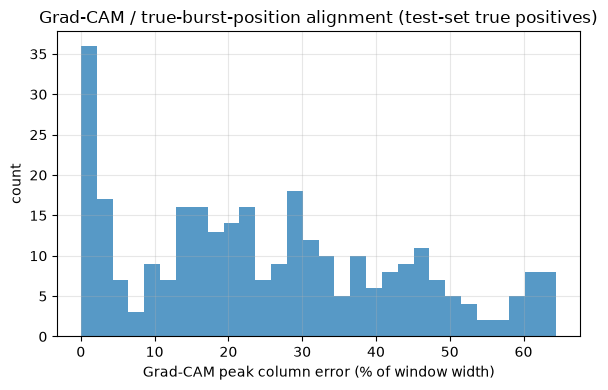


A large fraction of predictions have attention far from the real burst position --
this favors the shortcut-learning explanation and is worth investigating further
(e.g. re-check the simulator fixes from the earlier review, or inspect the false
positive/negative Grad-CAMs above for a pattern).


In [19]:
GRADCAM_QUANT_MAX = 300  # cap for speed; raise if you want the full test set

tp_idx_all = np.where((test_labels == 1) & (test_preds == 1))[0]
if len(tp_idx_all) > GRADCAM_QUANT_MAX:
    rng = np.random.default_rng(SEED)
    tp_idx_all = rng.choice(tp_idx_all, size=GRADCAM_QUANT_MAX, replace=False)

col_errors_bins = []
col_errors_frac = []
n_missing_metadata = 0

for i in tp_idx_all:
    try:
        meta = np.load(test_paths[i], allow_pickle=True)["metadata"].item()
        pos_frac = meta.get("burst_pos_frac", None)
    except Exception:
        pos_frac = None
    if pos_frac is None:
        n_missing_metadata += 1
        continue

    img = torch.from_numpy(test_imgs[i:i + 1]).to(device)
    cam = gradcam(img)
    # Collapse to a 1D time-axis profile (max over frequency) and take its peak --
    # the single column the model's evidence is most concentrated on.
    time_profile = cam.max(axis=0)
    peak_col = int(np.argmax(time_profile))

    expected_col = pos_frac * (TIME_BINS - 1)
    err_bins = abs(peak_col - expected_col)
    col_errors_bins.append(err_bins)
    col_errors_frac.append(err_bins / TIME_BINS)

if n_missing_metadata:
    print(f"Skipped {n_missing_metadata}/{len(tp_idx_all)} true positives -- no 'burst_pos_frac' in "
          f"metadata (regenerate with the fixed simulate_frbs_fitburst.py to enable this check).")

if col_errors_frac:
    errs = np.array(col_errors_frac)
    print(f"Checked {len(errs)} true-positive FRBs")
    print(f"  median alignment error: {np.median(errs) * 100:.1f}% of window width "
          f"({np.median(col_errors_bins):.1f} bins)")
    print(f"  mean alignment error:   {errs.mean() * 100:.1f}% of window width")
    print(f"  90th percentile error:  {np.percentile(errs, 90) * 100:.1f}% of window width")
    frac_within_10pct = (errs < 0.10).mean()
    print(f"  fraction within 10% of window width of the true position: {frac_within_10pct:.1%}")

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(errs * 100, bins=30, color="tab:blue", alpha=0.75)
    ax.set_xlabel("Grad-CAM peak column error (% of window width)")
    ax.set_ylabel("count")
    ax.set_title("Grad-CAM / true-burst-position alignment (test-set true positives)")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTDIR, "gradcam_alignment_hist.png"), dpi=150)
    plt.show()

    if frac_within_10pct > 0.7:
        print("\nMost of the model's attention lands close to the real burst position -- this is")
        print("real evidence FOR morphology learning, not just a shortcut.")
    else:
        print("\nA large fraction of predictions have attention far from the real burst position --")
        print("this favors the shortcut-learning explanation and is worth investigating further")
        print("(e.g. re-check the simulator fixes from the earlier review, or inspect the false")
        print("positive/negative Grad-CAMs above for a pattern).")
else:
    print("No true positives had usable metadata for this check.")

### 9.8 Summary

Everything from this run is saved under `OUTDIR`:
- `best_model.pt` -- best checkpoint by validation F1
- `history.json` -- per-epoch train/val metrics
- `test_metrics.json` -- final test-set metrics
- `training_curves.png`, `confusion_matrix.png`, `roc_pr_curves.png`, `example_predictions.png`,
  `gradcam_examples.png`, `gradcam_alignment_hist.png`

In [20]:
print(f"acc      = {test_metrics['acc']:.3f}")
print(f"precision= {test_metrics['precision']:.3f}")
print(f"recall   = {test_metrics['recall']:.3f}")
print(f"f1       = {test_metrics['f1']:.3f}")
print(f"ROC AUC  = {roc_auc:.3f}")
print(f"PR AUC   = {ap:.3f}")
print(f"best checkpoint: epoch {ckpt['epoch']}  (saved to {best_path})")

acc      = 0.982
precision= 0.980
recall   = 0.982
f1       = 0.981
ROC AUC  = 0.997
PR AUC   = 0.998
best checkpoint: epoch 12  (saved to runs/exp3/best_model.pt)
